In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [42]:
# Choose correct data files:

df_temp = pd.read_csv('target_temp_SEE_quadr_moanom.csv')

In [43]:
df_temp['time'] = pd.to_datetime(df_temp['time'])
df_temp

,time,t2m
0,1950-12-04,3.302433
1,1950-12-05,3.860399
2,1950-12-06,4.325744
3,1950-12-07,4.585810
4,1950-12-08,4.671236
...,...,...
6295,2025-02-21,-2.939421
6296,2025-02-22,-2.457508
6297,2025-02-23,-1.615634
6298,2025-02-24,-0.545681


In [44]:
df_temp_train = df_temp[df_temp['time'] < "2010-07"]
df_temp_test = df_temp[df_temp['time'] > "2010-07"]

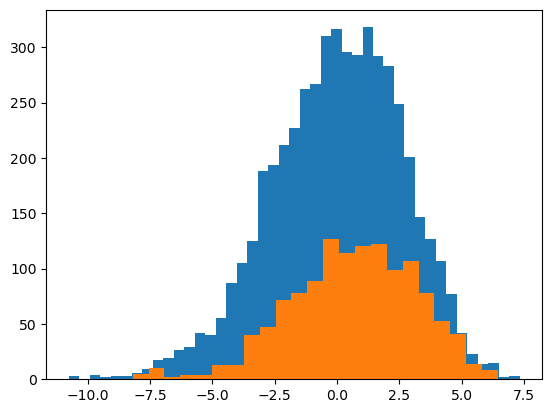

In [45]:
plt.hist(df_temp_train['t2m'], bins='auto')
plt.hist(df_temp_test['t2m'], bins='auto')
plt.show()

In [46]:
lower_quantile_temp = df_temp_train.quantile([0.1])['t2m'].values[0]
print(lower_quantile_temp)

-3.4053787174318


In [47]:
df_temp['quantile_category'] = 0
df_temp['quantile_category'] = df_temp['quantile_category'].where(df_temp['t2m'] > lower_quantile_temp, 1)

In [48]:
df_temp

,time,t2m,quantile_category
0,1950-12-04,3.302433,0
1,1950-12-05,3.860399,0
2,1950-12-06,4.325744,0
3,1950-12-07,4.585810,0
4,1950-12-08,4.671236,0
...,...,...,...
6295,2025-02-21,-2.939421,0
6296,2025-02-22,-2.457508,0
6297,2025-02-23,-1.615634,0
6298,2025-02-24,-0.545681,0


In [49]:
df_temp = df_temp.drop(['t2m'], axis=1).set_index('time')

In [50]:
print(len(df_temp[(df_temp.index < "2010-07") & (df_temp['quantile_category'] == 0)])/5040)
print(len(df_temp[(df_temp.index < "2010-07") & (df_temp['quantile_category'] == 1)])/5040)

0.9
0.1


In [51]:
print(len(df_temp[(df_temp.index > "2010-07") & (df_temp['quantile_category'] == 0)])/1260)
print(len(df_temp[(df_temp.index > "2010-07") & (df_temp['quantile_category'] == 1)])/1260)

0.9436507936507936
0.05634920634920635


In [68]:
# Name data files appropriately:

df_temp.to_csv('westerncentral_temperature_10_cat.csv')